# 04 Evaluate, benchmark, predict everything and chart (all models together)

Shared step of `03b_training_pipeline_model`: it loads the retrained models saved by `<model folder>/03_retrain.ipynb` (4 model types x 3 training
windows = 12 models), so nothing is retrained here and it does not depend on which folder was rerun last.

1. **Evaluation on train + validation.** The retrained models are scored on the whole train + validation period (2021-01 to 2025-03) with log R2,
   dollar R2, log RMSE and dollar RMSE. Every model was fitted on train + validation, so this is in-sample, not out-of-sample accuracy. Two versions:
   all months (a window model is *extrapolating backwards* for the months before its window starts, which is why the later windows look poor there) and
   only the months of the model's own window.
2. **Benchmark against the government growth band (0.5-3%).** The test set has no rents, so the same fixed flats (all flats approved in 2025-01 to
   2025-03) are predicted as if approved in each month. `growth at mid-2026` is the mean predicted rent of those flats in 2026-06 over their mean
   predicted rent in 2025-01..03. A model inside the band has distance 0; otherwise the distance is how far outside it is. The best model has the
   smallest distance (ties go to the lowest validation log RMSE).
3. **Predictions for every row**, 2021 to the end of the dataset, with the five composite keys, `FLAT_TYPE`, `FLAT_MODEL`, `FLOOR_AREA_SQM`,
   `LEASE_COMMENCE_DATE` and a column per model, written to `outputs/predictions_all_models.csv`.
4. **Charts** of the models' predictions against actual rent and the government growth scenarios, one chart per training window (3 in total).

In [1]:
import importlib.util
import os
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SHARED_DIR = '/Users/keltonn/Desktop/Projects/housing_price_regressor/03b_training_pipeline_model'
sys.path.insert(0, SHARED_DIR)
import pipeline_utils as pu
import plotting

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220)
GROWTH_BAND = (0.005, 0.03)                       # government rental growth by mid-2026 relative to the 2025 level
Q1_2025, MID_2026, MONTHS_2026 = [48, 49, 50], 65, list(range(60, 67))      # month indices: 2025-01..03, 2026-06, 2026-01..07
OUT_DIR = f'{SHARED_DIR}/outputs'
OUT_CSV = f'{OUT_DIR}/predictions_all_models.csv'
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Load the retrained models and the data

In [2]:
def load_py(path):
    """Import a config file by path (every model folder has its own feature_config.py / model_config.py)."""
    spec = importlib.util.spec_from_file_location(os.path.basename(path)[:-3], path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


WINDOWS = list(pu.WINDOW_START)
FAMILIES = list(pu.FAMILIES)
KEYS_ORDER = [f'{w}/{f}' for w in WINDOWS for f in FAMILIES]                     # window-major, as in the 03_training_pipeline outputs
setups = {}
fitted = {}
for family in FAMILIES:
    setups.update(load_py(f'{SHARED_DIR}/{family}/model_config.py').BEST_SETUPS)
    for window in WINDOWS:
        fitted[f'{window}/{family}'] = joblib.load(f'{SHARED_DIR}/{family}/outputs/{window}.joblib')
fitted = {key: fitted[key] for key in KEYS_ORDER}
print(len(fitted), 'retrained models loaded from the model folders:', ', '.join(fitted))

12 retrained models loaded from the model folders: full_history/two_stage_rf, full_history/two_stage_rf_ridge, full_history/single_stage_lasso, full_history/single_stage_ridge, from_2023/two_stage_rf, from_2023/two_stage_rf_ridge, from_2023/single_stage_lasso, from_2023/single_stage_ridge, from_2023_06/two_stage_rf, from_2023_06/two_stage_rf_ridge, from_2023_06/single_stage_lasso, from_2023_06/single_stage_ridge


In [3]:
frames, numeric, onehot = pu.load_static()
temporal = pu.load_temporal()
splits = ('train', 'validation', 'test')
arrays = {s: (pu.design(frames[s], numeric, onehot), frames[s]['month'].to_numpy()) for s in splits}
tv = pd.concat([frames['train'], frames['validation']], ignore_index=True)
X_tv, y_tv, m_tv = pu.design(tv, numeric, onehot), pu.log_rent(tv), tv['month'].to_numpy()
print(f'train + validation {X_tv.shape}; rows to predict: ' + ', '.join(f'{s} {len(arrays[s][1]):,}' for s in splits))

train + validation (149359, 237); rows to predict: train 132,398, validation 16,961, test 42,236


## 2. Evaluation on the full train + validation period

R2 and RMSE on the log scale (what the models are fitted on) and in dollars. The models are fitted on train + validation, so these are in-sample scores.

In [4]:
pred = {key: {s: pu.predict_model(f, X, m) for s, (X, m) in arrays.items()} for key, f in fitted.items()}
pred_tv = {key: np.concatenate([p['train'], p['validation']]) for key, p in pred.items()}

all_months = pd.DataFrame({key: pu.score(y_tv, pred_tv[key]) for key in fitted}).T
in_window = pd.DataFrame({key: pu.score(y_tv[m_tv >= pu.WINDOW_START[key.split('/')[0]]], pred_tv[key][m_tv >= pu.WINDOW_START[key.split('/')[0]]])
                          for key in fitted}).T
in_window.insert(0, 'rows', [int((m_tv >= pu.WINDOW_START[key.split('/')[0]]).sum()) for key in fitted])
display(all_months.round(4).rename_axis('all months of train + validation (2021-01..2025-03)'))
display(in_window.round(4).rename_axis("only the months of each model's own window"))

,log_r2,dollar_r2,log_rmse,dollar_rmse
all months of train + validation (2021-01..2025-03),,,,
full_history/two_stage_rf,0.6019,0.6355,0.1807,452.7992
full_history/two_stage_rf_ridge,0.6019,0.6355,0.1807,452.8085
full_history/single_stage_lasso,0.5400,0.5702,0.1943,491.6696
full_history/single_stage_ridge,0.5407,0.5710,0.1941,491.2301
from_2023/two_stage_rf,0.1857,0.2702,0.2585,640.7056
from_2023/two_stage_rf_ridge,0.2581,0.3431,0.2467,607.8523
from_2023/single_stage_lasso,0.2228,0.3082,0.2525,623.7941
from_2023/single_stage_ridge,0.2223,0.3009,0.2526,627.0996
from_2023_06/two_stage_rf,0.0631,0.1412,0.2772,695.0431


,rows,log_r2,dollar_r2,log_rmse,dollar_rmse
only the months of each model's own window,,,,,
full_history/two_stage_rf,149359,0.6019,0.6355,0.1807,452.7992
full_history/two_stage_rf_ridge,149359,0.6019,0.6355,0.1807,452.8085
full_history/single_stage_lasso,149359,0.5400,0.5702,0.1943,491.6696
full_history/single_stage_ridge,149359,0.5407,0.5710,0.1941,491.2301
from_2023/two_stage_rf,79177,0.3967,0.4579,0.1987,520.4826
from_2023/two_stage_rf_ridge,79177,0.3988,0.4591,0.1983,519.8732
from_2023/single_stage_lasso,79177,0.3247,0.3794,0.2102,556.8923
from_2023/single_stage_ridge,79177,0.3258,0.3804,0.2100,556.4223
from_2023_06/two_stage_rf,64458,0.4063,0.4743,0.1918,501.0592


## 3. Benchmark against the government growth band (test period)

The same fixed flats (those approved in 2025-01..03) are predicted as if approved in each month, so the comparison holds the flat mix constant and treats
all model families alike.

In [5]:
lo, hi = GROWTH_BAND
X_ref = X_tv[np.isin(m_tv, Q1_2025)]
rows = []
for key, f in fitted.items():
    levels = pu.fixed_flat_levels(f, X_ref, sorted(set(Q1_2025 + [MID_2026] + MONTHS_2026)))
    level_2025 = np.mean([levels[m] for m in Q1_2025])
    g_mid = levels[MID_2026] / level_2025 - 1
    g_avg = np.mean([levels[m] for m in MONTHS_2026]) / level_2025 - 1
    rows.append({'model': key, 'growth at mid-2026': g_mid, 'avg 2026 growth': g_avg, 'distance to 0.5-3% band': max(0.0, lo - g_mid, g_mid - hi),
                 'validation log RMSE': setups[key]['validation']['log_rmse']})
bench = pd.DataFrame(rows).set_index('model')
order = bench.sort_values(['distance to 0.5-3% band', 'validation log RMSE']).index
bench['rank'] = [list(order).index(m) + 1 for m in bench.index]
best_model = order[0]
show = bench.copy()
for c in ('growth at mid-2026', 'avg 2026 growth', 'distance to 0.5-3% band'):
    show[c] = (show[c] * 100).round(2).astype(str) + '%'
display(show.sort_values('rank'))
print('best model on the test set:', best_model)

,growth at mid-2026,avg 2026 growth,distance to 0.5-3% band,validation log RMSE,rank
model,,,,,
from_2023_06/single_stage_lasso,2.54%,3.28%,0.0%,0.17883,1
from_2023_06/single_stage_ridge,2.06%,2.75%,0.0%,0.17946,2
from_2023_06/two_stage_rf,3.8%,4.3%,0.8%,0.17695,3
from_2023_06/two_stage_rf_ridge,4.69%,5.06%,1.69%,0.17695,4
from_2023/two_stage_rf,5.24%,5.05%,2.24%,0.17625,5
from_2023/two_stage_rf_ridge,5.76%,5.71%,2.76%,0.17587,6
from_2023/single_stage_ridge,7.05%,7.07%,4.05%,0.18088,7
from_2023/single_stage_lasso,8.15%,8.03%,5.15%,0.18120,8
full_history/single_stage_lasso,60.34%,46.8%,57.34%,0.18147,9


best model on the test set: from_2023_06/single_stage_lasso


## 4. Predictions for every row, 2021 to the end of the dataset

Each row carries the five composite keys plus `FLAT_TYPE`, `FLAT_MODEL`, `FLOOR_AREA_SQM` and `LEASE_COMMENCE_DATE` (unscaled, as in the raw feature files).

In [6]:
# the flat attributes that, with the composite keys, identify a unit: read from the raw feature files by ROW_ID (the validation rows are rows of the raw train file)
FLAT_COLS = ['FLAT_TYPE', 'FLAT_MODEL', 'FLOOR_AREA_SQM', 'LEASE_COMMENCE_DATE']
raw_flat = {name: pd.read_csv(f'{pu.DATA}/raw_static_features/{name}_feature_raw.csv', usecols=pu.KEYS + FLAT_COLS) for name in ('train', 'test')}


def with_flat_attributes(split):
    rows = frames[split][pu.KEYS + ['ROW_ID']].reset_index(drop=True)
    raw = raw_flat['test' if split == 'test' else 'train'].iloc[rows['ROW_ID'].to_numpy()].reset_index(drop=True)
    assert (raw[pu.KEYS].to_numpy() == rows[pu.KEYS].to_numpy()).all(), 'ROW_ID does not point at the same flat in the raw feature file'
    return pd.concat([rows, raw[FLAT_COLS]], axis=1).assign(split=split)


out = pd.concat([with_flat_attributes(s) for s in splits], ignore_index=True)
col_of = {key: 'pred_' + key.replace('/', '_') for key in fitted}
for key, col in col_of.items():
    out[col] = np.concatenate([np.exp(pred[key][s]) for s in splits]).round(2)      # predicted monthly rent in dollars
out = out[pu.KEYS + FLAT_COLS + ['split', 'ROW_ID'] + list(col_of.values())]
out.to_csv(OUT_CSV, index=False, float_format='%.2f')     # dollars to the cent
first, last = out['RENT_APPROVAL_YEAR'].min(), out['RENT_APPROVAL_YEAR'].max()
print(f'wrote {OUT_CSV}: {out.shape[0]:,} rows, {out.shape[1]} columns; rows per split {out["split"].value_counts().to_dict()}; '
      f'{first}-{out.loc[out.RENT_APPROVAL_YEAR == first, "RENT_APPROVAL_MONTH"].min():02d} to {last}-{out.loc[out.RENT_APPROVAL_YEAR == last, "RENT_APPROVAL_MONTH"].max():02d}')
out.head()

wrote /Users/keltonn/Desktop/Projects/housing_price_regressor/03b_training_pipeline_model/outputs/predictions_all_models.csv: 191,595 rows, 23 columns; rows per split {'train': 132398, 'test': 42236, 'validation': 16961}; 2021-01 to 2026-07


,RENT_APPROVAL_YEAR,RENT_APPROVAL_MONTH,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,LEASE_COMMENCE_DATE,split,...,pred_full_history_single_stage_lasso,pred_full_history_single_stage_ridge,pred_from_2023_two_stage_rf,pred_from_2023_two_stage_rf_ridge,pred_from_2023_single_stage_lasso,pred_from_2023_single_stage_ridge,pred_from_2023_06_two_stage_rf,pred_from_2023_06_two_stage_rf_ridge,pred_from_2023_06_single_stage_lasso,pred_from_2023_06_single_stage_ridge
0,2021,1,punggol,604a,punggol road,4 room,model a,93.0,2012,train,...,2009.569946,2030.780029,2918.39,2793.00,2798.659912,2824.979980,3031.95,3036.21,3108.189941,3048.260010
1,2021,1,sengkang,290c,compassvale crescent,5 room,improved,110.0,2001,train,...,2064.050049,2051.879883,3043.63,2912.86,2865.340088,2876.389893,3138.86,3143.27,3173.560059,3193.239990
2,2021,1,queenstown,5,ghim moh road,3 room,improved,65.0,1976,train,...,1991.099976,2003.609985,2697.38,2581.48,2607.000000,2612.649902,2859.64,2863.66,2808.659912,2839.250000
3,2021,1,sengkang,436b,fernvale road,4 room,model a,96.0,2010,train,...,2031.310059,2023.119995,2858.09,2735.29,2805.469971,2905.070068,2929.62,2933.74,3049.479980,3174.820068
4,2021,1,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,2001,train,...,1845.150024,1833.310059,2798.59,2678.34,2606.750000,2725.429932,2901.17,2905.25,2917.580078,2938.090088


## 5. Charts of every model's predictions, one per training window

Three charts, one for each training window (full history, 2023 onward, after May 2023), each with the four model types of that window. Each chart has
the same layout as the 02b charts, on one shared dollar axis: the two-stage models, the single-stage models, and both against the government growth
scenarios (+0.5%, +1%, +2%, +3% by mid-2026 from the 2025 level, taken as the average actual rent of 2025-01..03; dotted blue lines, time axis from 2024).
One colour per model family. Lines are the monthly mean predicted rent; left of the divider they are the fit to the train + validation flats, right of it
the forecast for the test flats (different flats, so the lines do not join exactly at 2025-03). The dollar axis is scaled to each chart, so the
full-history chart is much taller than the other two.

/Users/keltonn/Desktop/Projects/housing_price_regressor/03b_training_pipeline_model/outputs/prediction_chart_full_history.png


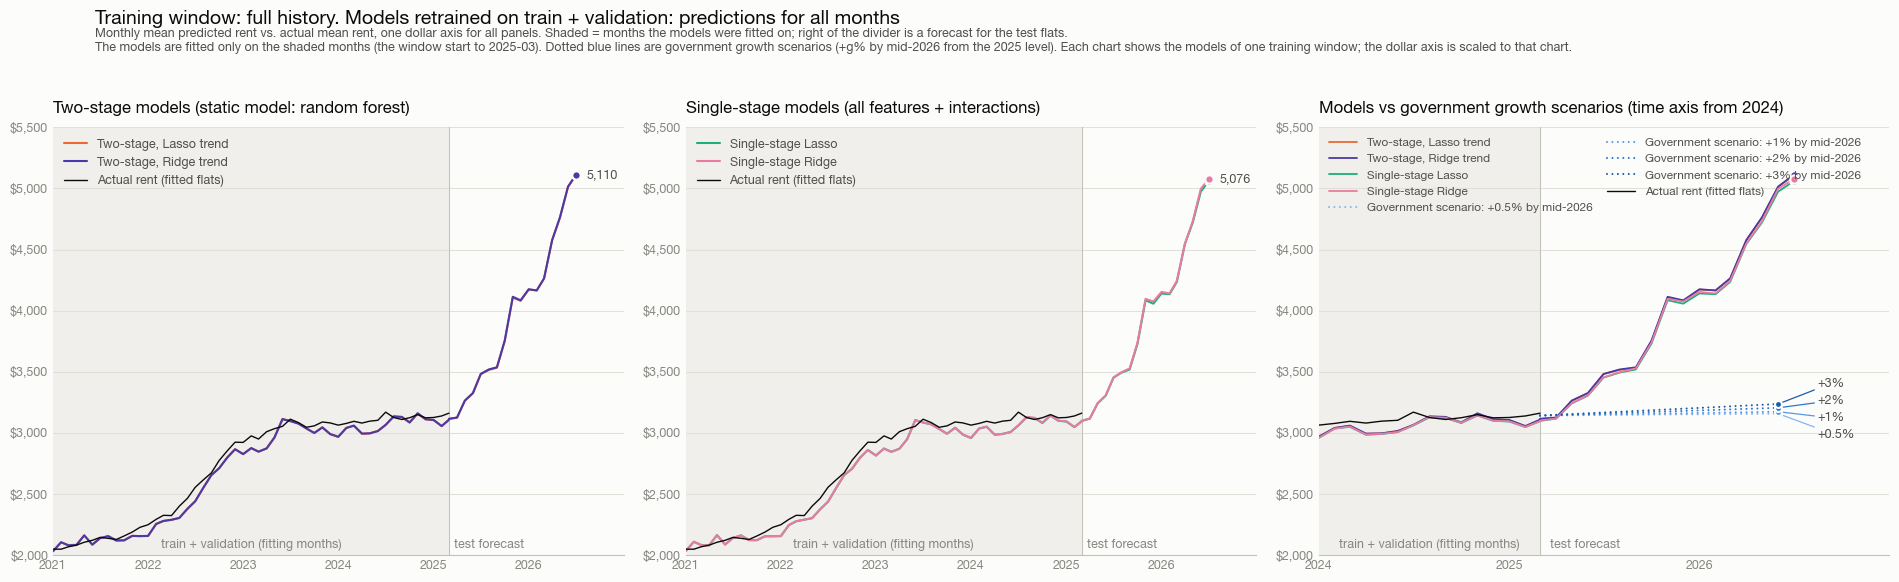

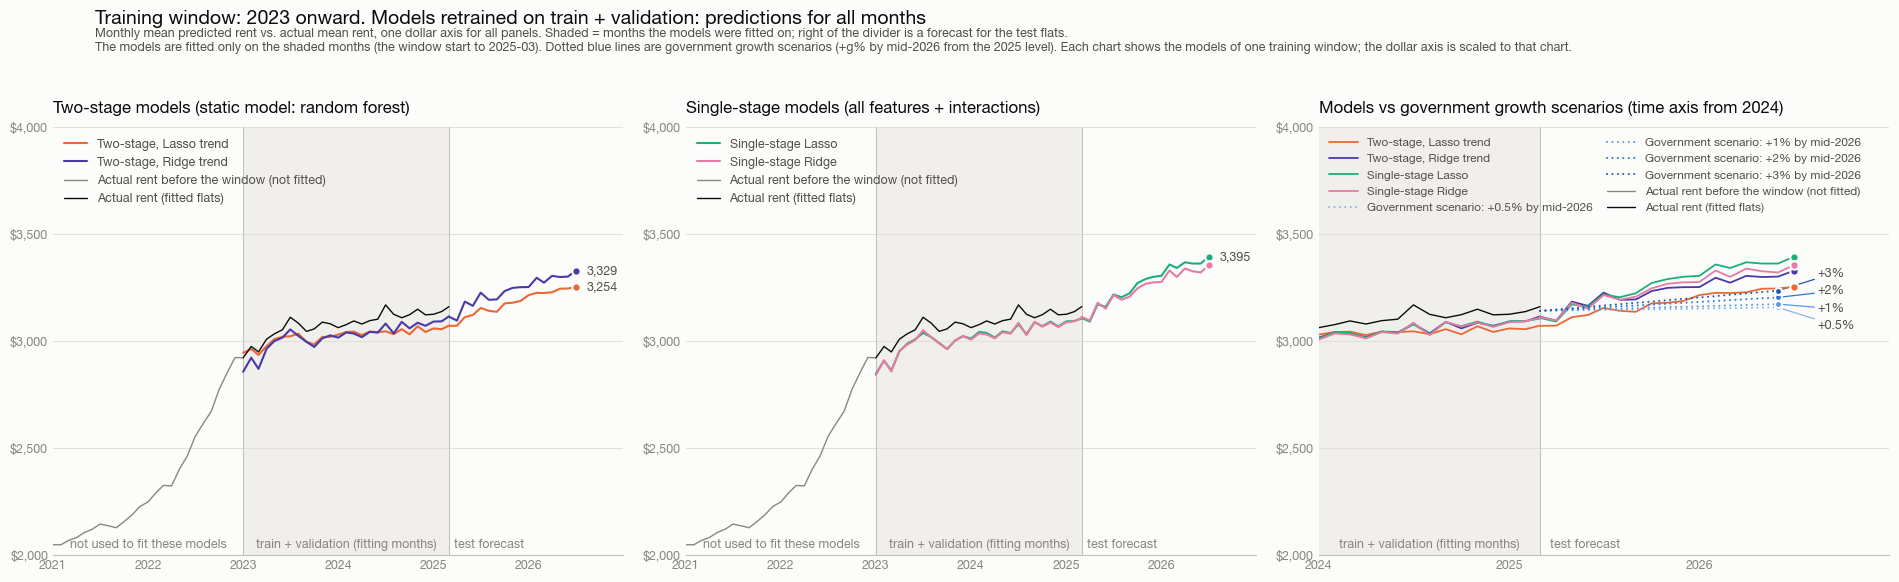

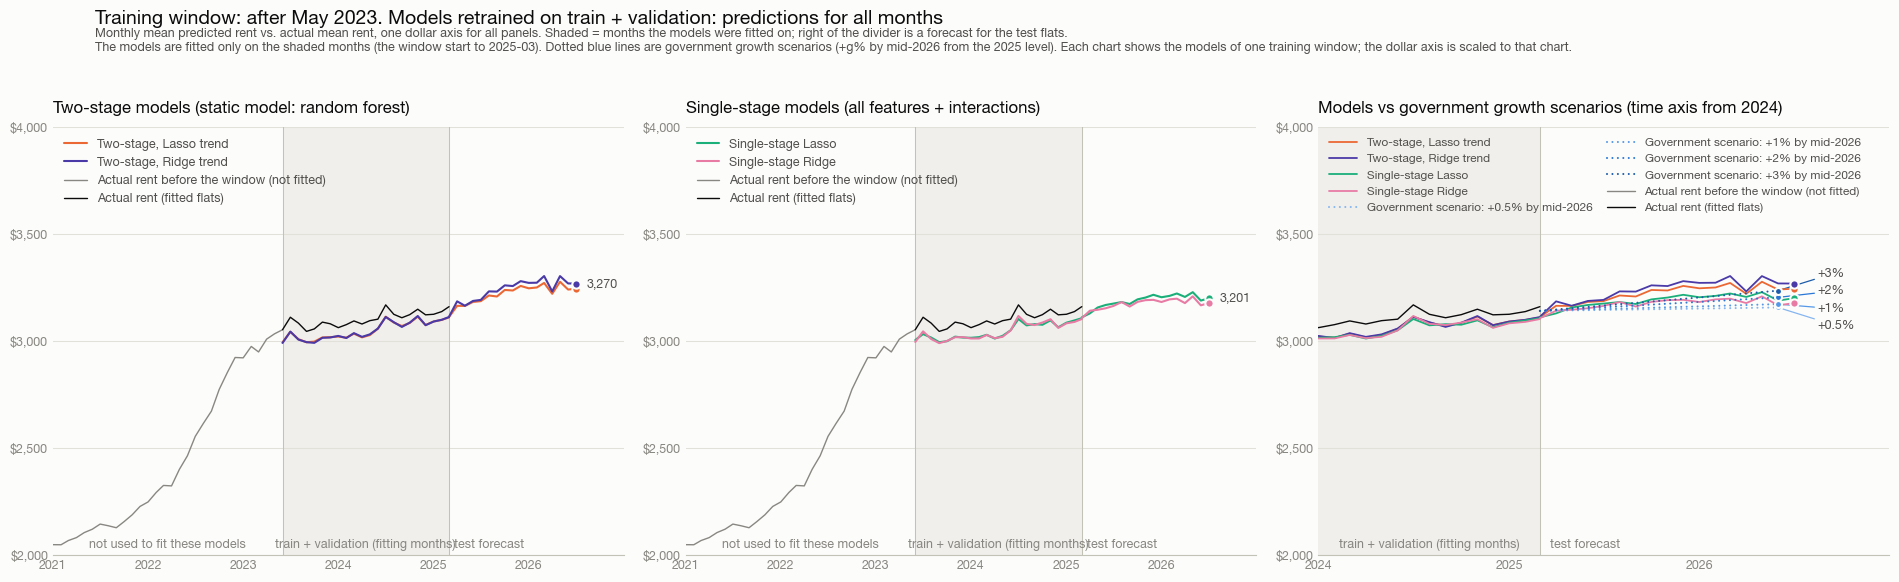

/Users/keltonn/Desktop/Projects/housing_price_regressor/03b_training_pipeline_model/outputs/prediction_chart_from_2023.png
/Users/keltonn/Desktop/Projects/housing_price_regressor/03b_training_pipeline_model/outputs/prediction_chart_from_2023_06.png


In [7]:
period = pd.PeriodIndex(year=out['RENT_APPROVAL_YEAR'], month=out['RENT_APPROVAL_MONTH'], freq='M')
is_test = (out['split'] == 'test').to_numpy()
rename = {col: key for key, col in col_of.items()}
fit_monthly = out.loc[~is_test, list(col_of.values())].groupby(period[~is_test]).mean().rename(columns=rename)
forecast_monthly = out.loc[is_test, list(col_of.values())].groupby(period[is_test]).mean().rename(columns=rename)
actual = tv.groupby(pd.PeriodIndex(year=tv['RENT_APPROVAL_YEAR'], month=tv['RENT_APPROVAL_MONTH'], freq='M'))['MONTHLY_RENT'].mean()

figures = plotting.prediction_charts(fit_monthly, forecast_monthly, actual, OUT_DIR)      # prediction_chart_<window>.png
for window, fig in figures.items():
    print(f'{OUT_DIR}/prediction_chart_{window}.png')
    plt.show()